# 02 骨干网络比较（E1）

比较 ResNet18、MobileNetV2、EfficientNet-B0。固定 Freeze、Basic、数据划分、种子与预算，只改变骨干网络。

**前置条件：** 完成 01 数据准备；三个模型均从 ImageNet 预训练权重初始化。

全部模型选择只依据 **PlantVillage 验证集 Macro-F1**，本 Notebook 不读取 PlantVillage 测试图片或 PlantDoc。训练参数来自配置，默认 224×224、batch size 16、最多 10 轮、AdamW、交叉熵与 Early Stopping；改变配置前先记录理由。

`RUN_TRAINING=False` 时只读取配置和已有记录，不下载权重或训练。打开训练后，已完成且配置和数据指纹一致的候选自动跳过；未完成候选采用新的 run_id 重新训练，旧中断记录仍可识别。


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root():
    current = Path.cwd().resolve()
    for candidate in (current, *current.parents):
        for root in (candidate, candidate / "plant-disease-project"):
            if (root / "configs" / "base.yaml").is_file():
                return root
    raise FileNotFoundError("请在项目根目录或 notebooks 目录打开本 Notebook。")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_config, load_labels

BASE = load_config(PROJECT_ROOT / "configs" / "base.yaml")
EXPERIMENTS = load_config(PROJECT_ROOT / "configs" / "experiments.yaml")
LABELS = load_config(PROJECT_ROOT / "configs" / "labels.yaml")
CLASS_NAMES = [item["label"] for item in load_labels(PROJECT_ROOT)]
assert len(CLASS_NAMES) == 8 and len(set(CLASS_NAMES)) == 8
assert [item["label_index"] for item in LABELS["classes"]] == list(range(8))
print("项目目录：", PROJECT_ROOT)
print("类别数量：", len(CLASS_NAMES), "；随机种子：", BASE["seed"])


项目目录： /Users/qingjiarui/Desktop/深度学习课程作业/基于迁移学习的植物叶片病害识别与真实场景泛化优化研究/plant-disease-project
类别数量： 8 ；随机种子： 42


## 1. 查看计划与运行状态

先确认候选和基础配置。MPS 可用时优先使用，必要时回退 CPU。每个正式实验有独立目录，保存实际配置、标签、数据指纹、环境、状态、最佳权重和历史；不得把烟测结果用作模型选择。


In [4]:
from src.experiments import run_stage, stage_results, run_statuses, select_best, selected_run

STAGE = "E1"
RUN_TRAINING = True
SAVE_SELECTION = True

print("阶段：", STAGE)
print("候选：", EXPERIMENTS.get("baseline_models"))
print("基础训练参数：")
display(BASE["training"])
print("策略学习率：", BASE["training"].get("lr_by_strategy"))
print("已选择骨干：", EXPERIMENTS.get("selected_backbone"))
print("已选择微调：", EXPERIMENTS.get("selected_finetuning"))
print("已选择增强：", EXPERIMENTS.get("selected_augmentation"))
display(pd.DataFrame(run_statuses(PROJECT_ROOT)))


阶段： E1
候选： ['resnet18', 'mobilenet_v2', 'efficientnet_b0']
基础训练参数：


{'epochs': 10,
 'batch_size': 16,
 'optimizer': 'AdamW',
 'lr': 0.001,
 'lr_by_strategy': {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001},
 'weight_decay': 0.0001,
 'early_stopping': True,
 'patience': 3,
 'num_workers': 0,
 'monitor': 'val_macro_f1'}

策略学习率： {'freeze': 0.001, 'partial': 0.0001, 'full': 0.0001}
已选择骨干： None
已选择微调： None
已选择增强： None


,run_id,stage,model,finetuning,augmentation,status,smoke_test,epochs_completed,seconds,error
0,run_20261021T042510_f673d06c,E1,resnet18,freeze,basic,completed,True,1,1.024261,None


## 2. 运行本阶段训练

确认配置后，在上一格把 `RUN_TRAINING` 改为 `True`，重新运行上一格，再运行本格。训练过程可能持续较久；完成后查看下一节真实结果。训练异常会保留失败状态；内核被强制关闭时，状态和不完整文件仍可识别，重新运行会建立新实验。


In [5]:
if not RUN_TRAINING:
    print("训练关闭：目前只展示计划与已有结果。")
else:
    for run_dir in run_stage(PROJECT_ROOT, STAGE):
        print("已完成：", run_dir.name)


e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 1: train_loss=0.6010, val_macro_f1=0.7968
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 2: train_loss=0.3107, val_macro_f1=0.8547
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 3: train_loss=0.2640, val_macro_f1=0.8634
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 4: train_loss=0.2298, val_macro_f1=0.8598
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 5: train_loss=0.2168, val_macro_f1=0.8765
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 6: train_loss=0.1981, val_macro_f1=0.8884
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 7: train_loss=0.1987, val_macro_f1=0.8655
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 8: train_loss=0.1856, val_macro_f1=0.8907
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 9: train_loss=0.1842, val_macro_f1=0.8848
e1_resnet18_freeze_basic_s42_20261021T045915_afe6ff | epoch 10: train_loss=0.1710,

## 3. 汇总完成的实验与训练曲线

仅汇总当前八类、当前清单和当前阶段参数一致的已完成正式实验。`val_macro_f1` 是最佳验证轮次对应指标，训练耗时按实际记录读取。尚无结果时不生成占位指标；中断训练不参与比较。


,run_id,stage,model,finetuning,augmentation,seed,lr,val_macro_f1,val_accuracy,val_loss,best_epoch,epochs_completed,seconds,dataset_fingerprint
0,e1_efficientnet_b0_freeze_basic_s42_20261021T0...,E1,efficientnet_b0,freeze,basic,42,0.001,0.950244,0.960247,0.121426,10,10,564.835715,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
1,e1_mobilenet_v2_freeze_basic_s42_20261021T0506...,E1,mobilenet_v2,freeze,basic,42,0.001,0.903709,0.924912,0.215418,10,10,463.776880,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...
2,e1_resnet18_freeze_basic_s42_20261021T045915_a...,E1,resnet18,freeze,basic,42,0.001,0.898722,0.918728,0.251522,10,10,427.105395,65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6...


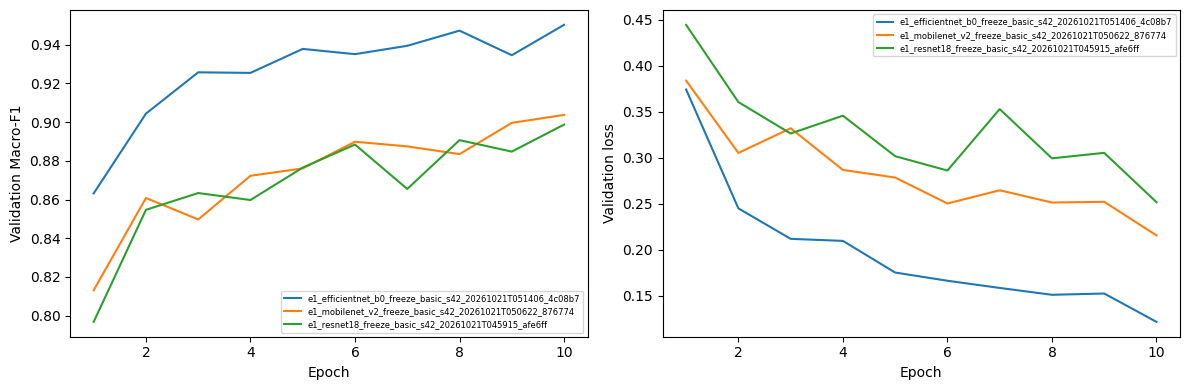

In [6]:
try:
    records = stage_results(PROJECT_ROOT, STAGE)
except (ValueError, FileNotFoundError) as error:
    records = []
    print("尚未满足数据准备或前置阶段条件：", error)
if not records:
    print("尚无本阶段完成的八分类正式结果。")
else:
    table = pd.DataFrame(records).sort_values("val_macro_f1", ascending=False)
    display(table)
    table_dir = PROJECT_ROOT / "outputs" / "tables"
    table_dir.mkdir(parents=True, exist_ok=True)
    table.to_csv(table_dir / f"{STAGE.lower()}_validation.csv", index=False, encoding="utf-8-sig")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for record in records:
        history = pd.read_csv(PROJECT_ROOT / "outputs" / "runs" / record["run_id"] / "history.csv")
        axes[0].plot(history["epoch"], history["val_macro_f1"], label=record["run_id"])
        axes[1].plot(history["epoch"], history["val_loss"], label=record["run_id"])
    axes[0].set(xlabel="Epoch", ylabel="Validation Macro-F1")
    axes[1].set(xlabel="Epoch", ylabel="Validation loss")
    for axis in axes:
        axis.legend(fontsize=6)
    plt.tight_layout()
    figure_dir = PROJECT_ROOT / "outputs" / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(figure_dir / f"{STAGE.lower()}_validation.png", dpi=160, bbox_inches="tight")
    plt.show()


## 4. 保存骨干网络选择

查看结果后，将第 1 节 `SAVE_SELECTION` 改为 `True`，重新运行该格，再运行本格。函数要求当前阶段的全部候选都已完成，再按验证集 Macro-F1 选择并写回 `configs/experiments.yaml` 的 `selected_*` 和 `selected_runs`。并列时使用固定规则，详细比较仍保留在表格与记录中。

选择后切换到下一本 Notebook；E3 选定实验就是 Notebook 05 最终评价和 06—07 展示的模型。不要根据测试集结果回头改选。


In [7]:
if not SAVE_SELECTION:
    print("尚未保存新选择；查看结果后将 SAVE_SELECTION 设为 True。")
else:
    try:
        selected = select_best(PROJECT_ROOT, STAGE)
        print("已按验证集结果保存选择：")
        display(selected)
    except (ValueError, FileNotFoundError) as error:
        print("尚不能选择：", error)


已按验证集结果保存选择：


{'run_id': 'e1_efficientnet_b0_freeze_basic_s42_20261021T051406_4c08b7',
 'stage': 'E1',
 'model': 'efficientnet_b0',
 'finetuning': 'freeze',
 'augmentation': 'basic',
 'seed': 42,
 'lr': 0.001,
 'val_macro_f1': 0.9502439016945723,
 'val_accuracy': 0.9602473498233216,
 'val_loss': 0.12142570551031091,
 'best_epoch': 10,
 'epochs_completed': 10,
 'seconds': 564.835715208,
 'dataset_fingerprint': '65e16a548fb193b9d39fdb5114591eeb9fd90d17afbfa6a28865d9b59300a815'}

In [8]:
from src.utils import load_config

config = load_config(
    PROJECT_ROOT / "configs/experiments.yaml"
)

print("选定骨干：", config["selected_backbone"])
print("选定微调策略：", config["selected_finetuning"])

选定骨干： efficientnet_b0
选定微调策略： None


## 结论记录

- **统一训练条件与设备：** 本实验采用 PlantVillage 番茄叶片八分类数据集，统一使用 ImageNet 预训练权重、224×224 输入尺寸、Batch Size 16、AdamW 优化器、学习率 0.001、随机种子 42，采用冻结骨干网络的迁移学习方式及基础数据增强，最多训练 10 轮，使用 Mac 的 MPS 进行加速。

- **各模型验证集表现与资源开销：** ResNet18、MobileNetV2 和 EfficientNet-B0 的最佳验证集 Macro-F1 分别为 0.8987、0.9037 和 0.9502，验证准确率分别为 91.87%、92.49% 和 96.02%，训练耗时分别约为 427.11 秒、463.78 秒和 564.84 秒。EfficientNet-B0 的分类表现最好，但计算开销相对较高。三种模型均在第 10 轮达到最佳验证结果，表明当前训练预算下可能尚未完全收敛。

- **选定骨干及选择依据：** 综合验证集指标，选择 EfficientNet-B0 作为后续实验的骨干网络。其 Macro-F1 比 ResNet18 高约 5.15 个百分点，比 MobileNetV2 高约 4.65 个百分点，同时具有最高的验证准确率和最低的验证损失。

- **与下一阶段保持一致的设置：** 后续微调策略对比实验固定使用 EfficientNet-B0，保持八分类标签、数据划分、输入尺寸和验证评价指标不变，分别比较 Freeze、Partial 和 Full 三种策略。学习率等训练参数以 E2 实际配置为准。本阶段仅使用随机种子 42，尚未检验跨随机种子的稳定性，最终泛化性能仍需通过独立测试集进行验证。